<a href="https://colab.research.google.com/github/TheBlackBoxLab/Machine-Learning-Assignments/blob/main/Chloe_Machine_Learning__1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [160]:
#connect my Google drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


1. What's the question
2. what did they record and in what shape
3. sanity check
4. Response variable
5. Summarize by condition, tuning

In [161]:
import os #operating system
os.listdir('/content/drive/MyDrive/ML_HW1')

['105l001p16_spikes.mat', 'Chloe_Machine_Learning_#1']

In [162]:
# loading file (needed v7.3 format, so we use h5py)
import h5py
path = '/content/drive/MyDrive/ML_HW1/105l001p16_spikes.mat'
f = h5py.File(path, 'r')

Context: Electrode array in visual cortex of monkey records 100 neurons at once. 3200 times, Should be around 400 times per angle (8 diff), in random order. Stimulus for 1280 ms. Does each neuron care which way the stripes are tilted = orientation tuning.

Part 1: For each neuron, look at angle vs avg spikes and find tuning curve (mean response across trials). Pick that neuron for rest of assignment.

In [163]:
list(f.keys())

['#refs#', 'spikes', 'stim']

In [164]:
# how is the stimulus list shaped?
f['stim'].shape
import numpy as np #to work with arrays
stim = np.array(f['stim']).flatten() #out of file into numpy and squashes into plain lists of 3200 numbers.
stim[:10]

array([3., 7., 5., 4., 1., 6., 8., 2., 7., 6.])

label codes. Assuming label 1=0 degrees and label 2=22.5 degress, etc.

In [165]:
# print trial number and orientation label/code for first 5 trials
for i in range(5):
    print(f"Trial {i+1}: orientation code {stim[i]}")

Trial 1: orientation code 3.0
Trial 2: orientation code 7.0
Trial 3: orientation code 5.0
Trial 4: orientation code 4.0
Trial 5: orientation code 1.0


In [166]:
#trials for each orientation code
for code in range(1, 9):
    count =(stim == code).sum()
    print(f"Code {code}: {count} trials")
print("=" *20)
#spike container
print(f['spikes'].shape) #how many slots
print(f['spikes'].dtype) #what is stored

Code 1: 400 trials
Code 2: 400 trials
Code 3: 400 trials
Code 4: 400 trials
Code 5: 400 trials
Code 6: 400 trials
Code 7: 400 trials
Code 8: 400 trials
(2, 1)
object


In [167]:
print(f['spikes'].shape)
print(f['spikes'].dtype)

(2, 1)
object


In [168]:
# want to grab V1 shortcut and check the size of the real array
v1_ref = f['spikes'][0, 0]       #grab shortcut in slot 0
v1 = f[v1_ref]                   #follow it to the real data (ref)
print(f"V1 array shape: {v1.shape}")   #check its size

V1 array shape: (3200, 1280, 159)


1. Trials= 3200
2. total ms =1280
3. Neurons =159

Now turn ms of 0s and 1s into one response per trial. So for each neuron in each trial, add up row of 0s and 1s.


In [169]:
#Trial 1, Orientation code 3 to understand what I'm looking for
trial1 = v1[0]                       # take trial 1's spreadsheet
print(f"Trial 1 shape: {trial1.shape}")
counts_trial1 = trial1.sum(axis=0)   # add up the milliseconds
print(f"Counts shape: {counts_trial1.shape}")
print(f"First 10 neuron's spike counts: {counts_trial1[:10]}")   # first 10 neurons' spike counts

Trial 1 shape: (1280, 159)
Counts shape: (159,)
First 10 neuron's spike counts: [28. 11. 13. 16. 28. 52.  1. 11. 27. 15.]


In [170]:
#Now for all trials, 3200 trials x 159 Neurons
counts = np.zeros((3200, 159))  # make an empty table filled with 0s

for trial in range(3200):
    counts[trial] = v1[trial].sum(axis=0) # fill one row per trial

print(f"Counts table shape: {counts.shape}")

Counts table shape: (3200, 159)


In [171]:
# neuron 1's average response to each orientation code
for code in range(1, 9):
    avg = counts[stim == code, 0].mean()
    print(f"Code {code}: {avg:.1f} spikes")

Code 1: 43.5 spikes
Code 2: 30.4 spikes
Code 3: 22.8 spikes
Code 4: 24.0 spikes
Code 5: 38.7 spikes
Code 6: 49.7 spikes
Code 7: 22.2 spikes
Code 8: 28.4 spikes


In [172]:
# average response of all neurons to each orientation code
tuning = np.zeros((8, 159)) # empty table: 8 codes x 159 neurons

for code in range(1, 9):
    tuning[code - 1] = counts[stim == code].mean(axis=0)

print(f"Tuning table shape: {tuning.shape}")
print("="*50)

# for each neuron, which code gave its highest average?
best_row = tuning.argmax(axis=0)   # axis=0: search down the 8 rows of each column
best_code = best_row + 1           # convert row number back to code number
print(f"Preferred codes, first 10 neurons: {best_code[:10]}")

Tuning table shape: (8, 159)
Preferred codes, first 10 neurons: [6 4 2 2 3 4 7 2 7 2]


In the previous cell, neuron's 1 preferred code was 6, matching what we see in this output: Neuron 1's had the highest average spike count for code 6.

In [173]:
#8 label/code into degrees
angles = (np.arange(1, 9) - 1) * 22.5
print(f"Angles: {angles}")

Angles: [  0.   22.5  45.   67.5  90.  112.5 135.  157.5]


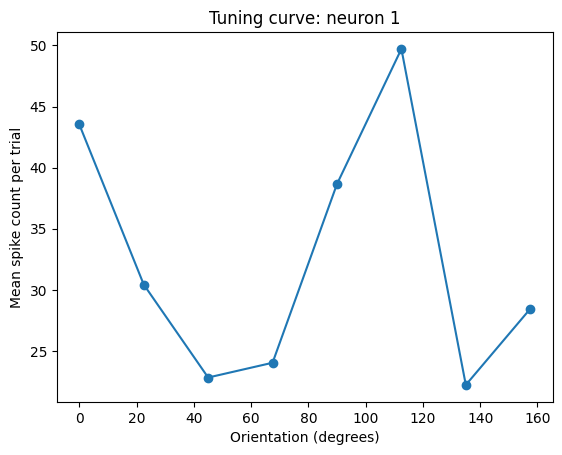

In [174]:
#neuron 1's tuning curve
import matplotlib.pyplot as plt

plt.plot(angles, tuning[:, 0], 'o-') #neuron 1’s 8 averages. The : means all rows of all 8 codes),  0 means column 0 (neuron 1)
plt.xlabel('Orientation (degrees)')
plt.ylabel('Mean spike count per trial')
plt.title('Tuning curve: neuron 1')
plt.show()

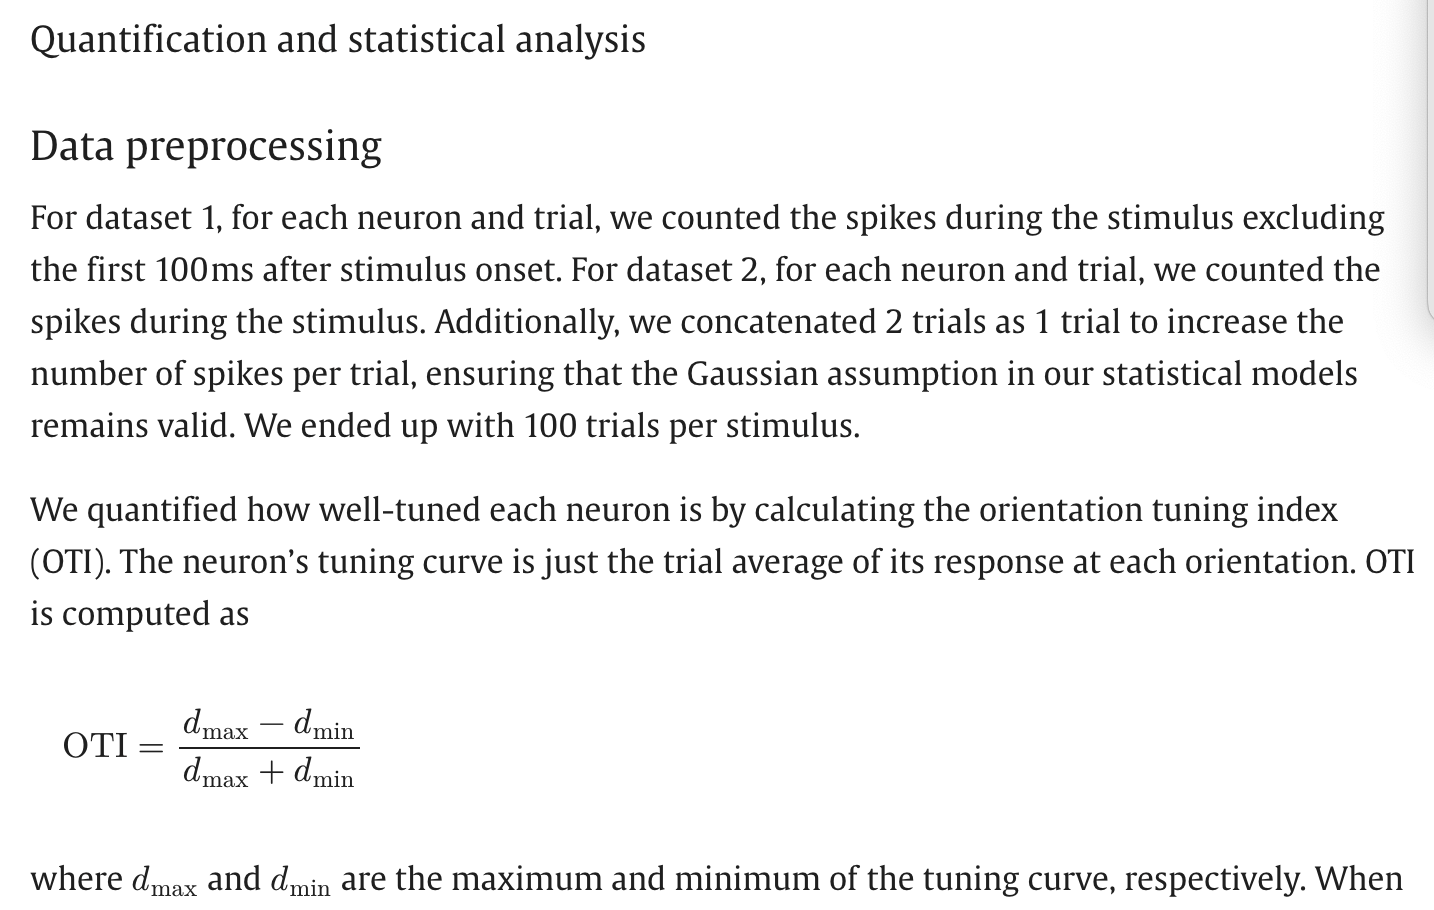

In [175]:
# Orientation Tuning Index (OTI) for every neuron
d_max = tuning.max(axis=0)    # highest average for each neuron
d_min = tuning.min(axis=0)    # lowest average for each neuron
oti = (d_max - d_min) / (d_max + d_min)

print(f"OTI shape: {oti.shape}")
print(f"OTI, first 10 neurons: {np.round(oti[:10], 2)}")

OTI shape: (159,)
OTI, first 10 neurons: [0.38 0.12 0.42 0.33 0.93 0.92 0.9  0.52 0.54 0.5 ]


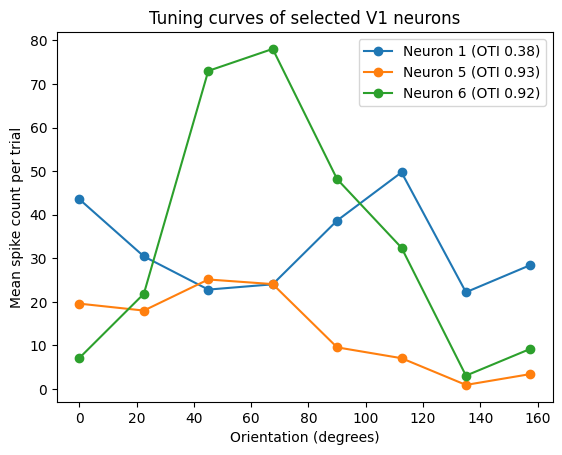

In [176]:
# compare tuning curves of neurons 1, 5 and 6
for n in [0, 4, 5]:
    plt.plot(angles, tuning[:, n], 'o-', label=f'Neuron {n+1} (OTI {oti[n]:.2f})')

plt.xlabel('Orientation (degrees)')
plt.ylabel('Mean spike count per trial')
plt.title('Tuning curves of selected V1 neurons')
plt.legend()
plt.show()

OTI measures the shape of the curve, not its height. It’s a ratio, so it only cares how close the lowest point gets to zero relative to the peak.

In [177]:
# how many neurons pass each firing cutoff?
for cutoff in [10, 25, 40]:
    n_pass = (d_max >= cutoff).sum()
    print(f"Peak >= {cutoff} spikes: {n_pass} neurons")

Peak >= 10 spikes: 123 neurons
Peak >= 25 spikes: 73 neurons
Peak >= 40 spikes: 39 neurons


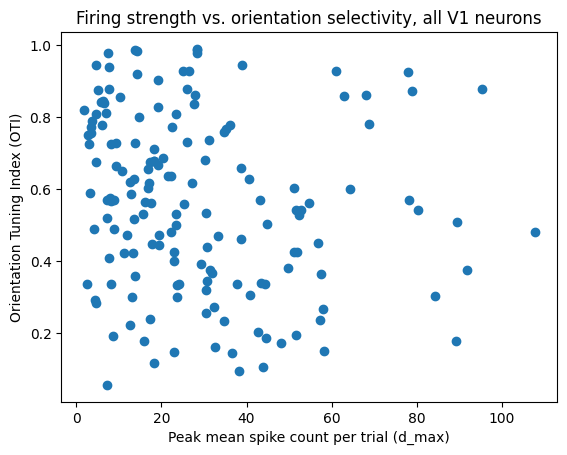

In [178]:
# is peak firing related to tuning sharpness?
plt.scatter(d_max, oti)
plt.xlabel('Peak mean spike count per trial (d_max)')
plt.ylabel('Orientation Tuning Index (OTI)')
plt.title('Firing strength vs. orientation selectivity, all V1 neurons')
plt.show()

In [179]:
# find neurons with peak between 30 and 40 spikes AND OTI above 0.9
match = (d_max > 30) & (d_max < 40) & (oti > 0.9)
candidates = np.where(match)[0]

for n in candidates:
    print(f"Neuron {n+1}: OTI {oti[n]:.2f}, peak {d_max[n]:.1f} spikes, preferred code {best_code[n]}")

Neuron 44: OTI 0.94, peak 38.9 spikes, preferred code 4


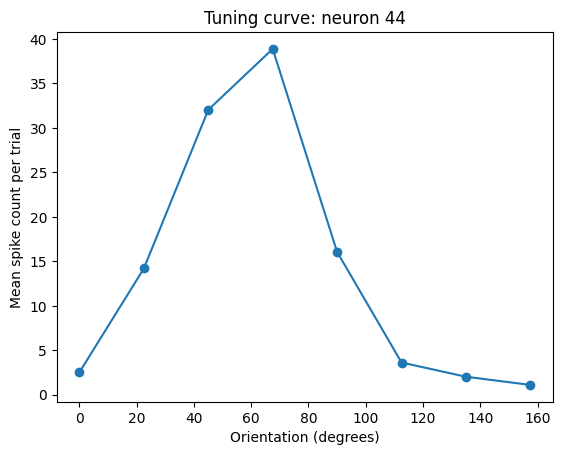

In [180]:
#neuron 44's tuning curve #prob my chosen neuron

plt.plot(angles, tuning[:, 43], 'o-')
plt.xlabel('Orientation (degrees)')
plt.ylabel('Mean spike count per trial')
plt.title('Tuning curve: neuron 44')
plt.show()

In [181]:
# untuned: low OTI (fires about the same at every angle)
untuned = np.where(oti < 0.2)[0]
print(f"Untuned neurons: {untuned[:5] + 1}")

Untuned neurons: [ 2 13 14 30 49]


In [182]:
moderate = np.where((d_max >10) & (d_max < 75) & (oti >.4) & (oti < 0.7))[0]
print(f"Moderate neurons: {moderate[:5] + 1}")

Moderate neurons: [ 3  8  9 10 11]


In [202]:
strong = np.where((d_max > 40) & (d_max < 100) & (oti > 0.71) & (oti < 1.1))[0]
print(f"Strong neurons: {strong[:5] + 1}")

Strong neurons: [  6  56  95  97 148]


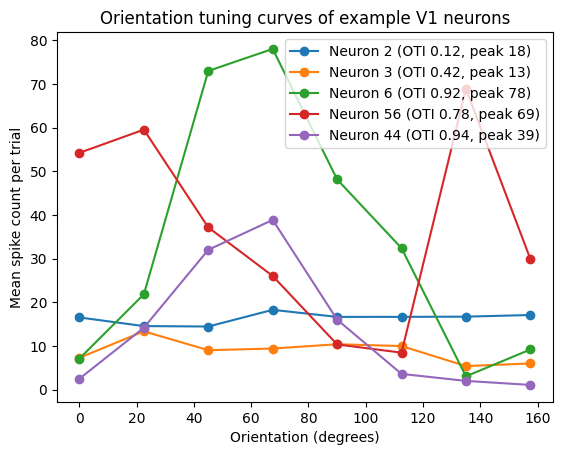

In [184]:
# Q4: tuning curves for example neurons across the range of selectivity
examples = [2, 3, 6, 56, 44]   # untuned, moderate, strong, strong, my neuron

for n in examples:
    col = n - 1
    plt.plot(angles, tuning[:, col], 'o-',
             label=f'Neuron {n} (OTI {oti[col]:.2f}, peak {d_max[col]:.0f})')

plt.xlabel('Orientation (degrees)')
plt.ylabel('Mean spike count per trial')
plt.title('Orientation tuning curves of example V1 neurons')
plt.legend()
plt.show()

In [185]:
# Picking neuron 6 for the rest of the assignment

**PART 2:** Fitting four models with a different degree.
1. data" x= angles and y=neuron's 8 averages.
2. fit: find the β's for degree d.
3. Evaluate fitted curve at many θ values
4. compute MSE at real 8 data points

Numpy does 2 and 3, being:
1.  np.polyfit(x, y, d) finds the β's.
2.  np.polyval(betas, x) computes R(θ) from them.

In [186]:
# Part 2: data for my chosen neuron
my_neuron = 6
col = my_neuron - 1
y = tuning[:, col]   # the 8 mean responses

# fit a degree-1 polynomial (straight line)
betas = np.polyfit(angles, y, 1)
print(f"Linear fit parameters: {betas}")

Linear fit parameters: [-0.12221958 43.73791667]


$$R(\theta) = 43.74 - 0.122\,\theta$$

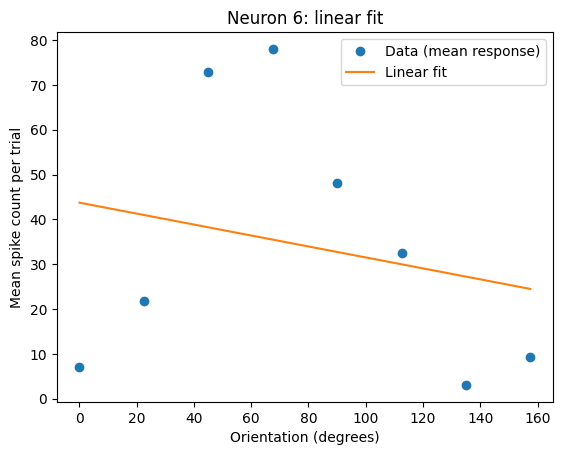

Linear fit MSE: 723.0937


In [187]:
# plot data and linear fit
theta_fine = np.linspace(0, 157.5, 200)     # 200 evenly spaced angles, for a smooth curve
R_linear = np.polyval(betas, theta_fine)    # model's prediction at each of them

plt.plot(angles, y, 'o', label='Data (mean response)')
plt.plot(theta_fine, R_linear, '-', label='Linear fit')
plt.xlabel('Orientation (degrees)')
plt.ylabel('Mean spike count per trial')
plt.title(f'Neuron {my_neuron}: linear fit')
plt.legend()
plt.show()

# MSE of the linear fit
y_pred = np.polyval(betas, angles)        # step 1: predictions at the 8 real angles
errors = y - y_pred                       # step 2
mse = np.mean(errors ** 2)                # steps 3 and 4 (** means "to the power of")
print(f"Linear fit MSE: {mse:.4f}")

Degree 1: 2 parameters, MSE = 723.0937
Degree 3: 4 parameters, MSE = 127.5350
Degree 4: 5 parameters, MSE = 52.0191
Degree 7: 8 parameters, MSE = 0.0000


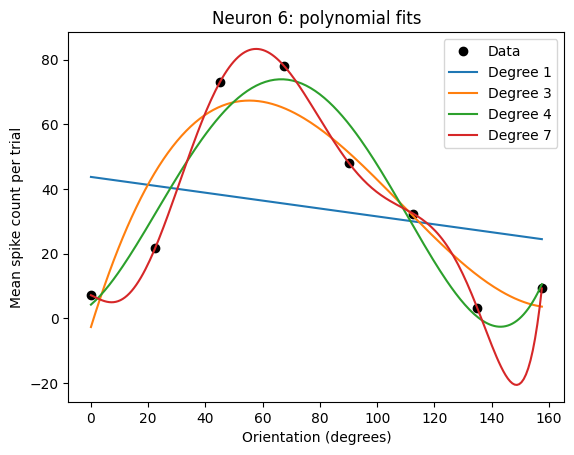

In [188]:
# fit and compare polynomials of several degrees
degrees = [1,3,4,7]

plt.plot(angles, y, 'o', color='black', label='Data')

for d in degrees:
    betas = np.polyfit(angles, y, d)                 # fit
    y_pred = np.polyval(betas, angles)               # predict at the real angles
    mse = np.mean((y - y_pred) ** 2)                 # score
    print(f"Degree {d}: {d+1} parameters, MSE = {mse:.4f}")
    plt.plot(theta_fine, np.polyval(betas, theta_fine), label=f'Degree {d}')  # draw

plt.xlabel('Orientation (degrees)')
plt.ylabel('Mean spike count per trial')
plt.title(f'Neuron {my_neuron}: polynomial fits')
plt.legend()
plt.show()

1. MSE alone (MSE=0), 7th order fits best because it passes through each of the 8 points because it has 8 parameters. Reflects how flexible and specific this model is, not how well it predicts or generalizes. 3rd/4th order follows the general shape and would generalize better.

2. The model fits the data better with each increase in degree, witht the MSE decreasing. The curve becomes more flexible and bendy/wiggly.

3. The polynomial degree controls the the complexity.

4. Advantages of using higher degree polynomial will capture a complex shape and fit the specific observed data closely with a low MSE. Disadvantage being it fits the noise rather than the actual tuning, or overfits, and will make a poor predictor.

5. Coefficients have no meaning being that they do not correspond to orientatio, tuning width, peak response, etc. A biological property would not depend on arbitrary modeling choices.

In [189]:
print(f"Degree 3 betas: {np.round(np.polyfit(angles, y, 3), 2)}")
print(f"Degree 4 betas: {np.round(np.polyfit(angles, y, 4), 2)}")

Degree 3 betas: [ 0.   -0.03  2.86 -2.7 ]
Degree 4 betas: [ 0.   -0.    0.03  0.76  4.23]


**Part 3 Nonlinear**
$$R(\theta) = B + A\,\exp\!\left[-\frac{(\theta-\mu)^2}{2\sigma^2}\right]$$

polyfit can’t do this. With polynomials, the β's just multiply known columns, so there’s a direct formula for the best β's. Here μ and σ sit inside the exponential, so no such formula exists.

Instead, the computer searches:

1. Start from a guess for B, A, μ, and σ.
2. Compute the MSE.
3. Nudge the parameters in whichever direction lowers the MSE.
4. Repeat until it stops improving.

Gradient descent. SciPy’s curve_fit does this search. It needs three things:
1. the model written as a Python function
2. the data  
3. starting guesses.

In [190]:
# Gaussian tuning model
def gaussian(theta, B, A, mu, sigma):
    return B + A * np.exp(-(theta - mu)**2 / (2 * sigma**2))

In [191]:
# interactive Gaussian: drag the sliders to fit by hand
from ipywidgets import interact

def plot_guess(B=5, A=70, mu=67.5, sigma=25):
    R_guess = gaussian(theta_fine, B, A, mu, sigma)
    mse = np.mean((y - gaussian(angles, B, A, mu, sigma)) ** 2)   # error at the 8 real points

    plt.plot(angles, y, 'o', color='black', label='Data')
    plt.plot(theta_fine, R_guess, label='Gaussian (hand guess)')
    plt.ylim(0, max(y) * 1.3)            # fixed y-axis, so the plot doesn't jump around
    plt.xlabel('Orientation (degrees)')
    plt.ylabel('Mean spike count per trial')
    plt.title(f'Hand fit: MSE = {mse:.1f}')
    plt.legend()
    plt.show()

interact(plot_guess, B=(0, 30, 1), A=(0, 100, 1), mu=(0, 157.5, 2.5), sigma=(2, 80, 1))

interactive(children=(IntSlider(value=5, description='B', max=30), IntSlider(value=70, description='A'), Float…

<function __main__.plot_guess(B=5, A=70, mu=67.5, sigma=25)>

a Gaussian I played around with and then tried to tuned by hand that nearly matches the polynomial 4-parameter of 127.5. Unlike the polynomial, each parameter means something, and we have fewer parameters, similar error, and its interpretable. Parsimony/occams razor.

In [192]:
# fit the Gaussian with scipy's curve_fit
from scipy.optimize import curve_fit

p0 = [5, 70, 67.5, 25]     # starting guesses: [B, A, mu, sigma]. Put your best slider values here!
params, cov = curve_fit(gaussian, angles, y, p0=p0)
B, A, mu, sigma = params

print(f"B (baseline)       = {B:.2f} spikes")
print(f"A (amplitude)      = {A:.2f} spikes")
print(f"mu (preferred ori) = {mu:.2f} degrees")
print(f"sigma (width)      = {abs(sigma):.2f} degrees")

B (baseline)       = 5.37 spikes
A (amplitude)      = 75.96 spikes
mu (preferred ori) = 63.91 degrees
sigma (width)      = 27.23 degrees


Gaussian MSE = 41.53


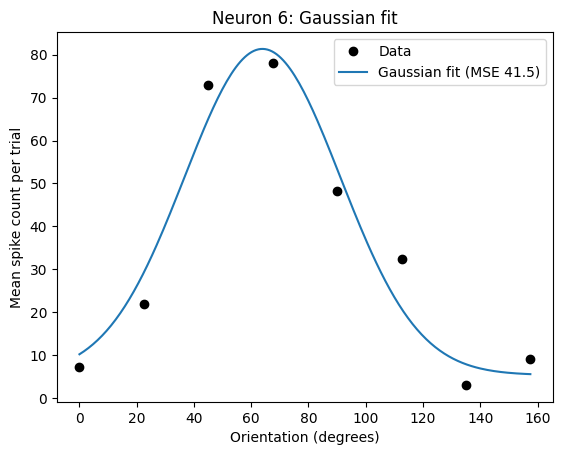

In [193]:
# MSE at the 8 real points, and plot
y_pred = gaussian(angles, *params)          # *params unpacks the 4 values into the function
mse_gauss = np.mean((y - y_pred) ** 2)
print(f"Gaussian MSE = {mse_gauss:.2f}")

plt.plot(angles, y, 'o', color='black', label='Data')
plt.plot(theta_fine, gaussian(theta_fine, *params), label=f'Gaussian fit (MSE {mse_gauss:.1f})')
plt.xlabel('Orientation (degrees)')
plt.ylabel('Mean spike count per trial')
plt.title(f'Neuron {my_neuron}: Gaussian fit')
plt.legend()
plt.show()

1. The 7th order polynomial model has MSE of zero but only because of the 8 parameters and 8 data points. The Gaussian model  with only 4 parameters has lowest MSE of 41.5, which is lower than both erd and 4th order polynomial.
2. The estimated preffered orientation mu is 63.9 degrees, although the highest measured response was around 70 degrees, which would suggest that the true peak lies between tested orientations.
3. Sigma is like the standard deviation of and measures tuning width so since it is 27.2 means the response is falling to half its peak above baseline, or about 32 degrees either side of orientation. Smaller sigma would mean sharper orientation selectivity.
4. All four have biological interpretation. Mu is neuron's preferred orientation, sigma is tuning width, B is the baseline resopnse, or the background firing to non-preferred orientations, and A is the amplitude or the additional firing driven by the preferred orientation above the baseline so peak should be around 81 spikes.
5. Nonlinear is preferable because it is biologically interpretable, it has similar accuracy with few parameters (parisomny), can be compared across other neurons.  

**Part 4 Circularity**

1. Gaussian treates orienation as ordinary number on straight line. Orientation is circular
2. if neuron prefers orientation 0 degrees, its tuning curve continues past 0 and wraps around to high end of axis. A neuron preferring 10 degrees should also respond well to 170 degrees. On a linear axis this single bump is split into two different pieces because distance is being measured linearly.
3. Polynomial Regression is also problematic for circular variable because it also treates orientation as linear.
4. My neuron #6 has preferred orientation around 63.9 degrees where its response falls back to baseline towards both edges where only a few spikes (5-10) are observed around 0 degrees and 160 degrees. Circularity would therefor only have a small affect on my neuron.

The von Mises function
$$R(\theta) = B + A\,\exp\big[\kappa\cos\big(2(\theta - \mu)\big)\big]$$

In [194]:
# von Mises tuning model (theta and mu in degrees)
def von_mises(theta, B, A, mu, kappa):
    return B + A * np.exp(kappa * np.cos(2 * np.deg2rad(theta - mu)))

y = tuning[:, my_neuron - 1]
print(f"Fitting neuron {my_neuron}: {np.round(y, 1)}")

# fit the von Mises model
p0_vm = [5, 16, 64, 1.5]     # [B, A, mu, kappa] starting guesses
params_vm, _ = curve_fit(von_mises, angles, y, p0=p0_vm, maxfev=10000)
B_vm, A_vm, mu_vm, kappa_vm = params_vm

print(f"B     = {B_vm:.2f}")
print(f"A     = {A_vm:.2f}")
print(f"mu    = {mu_vm:.2f} degrees")
print(f"kappa = {kappa_vm:.2f}")

Fitting neuron 6: [ 7.1 21.9 73.  78.  48.2 32.4  3.1  9.2]
B     = -6.18
A     = 31.39
mu    = 63.72 degrees
kappa = 1.03


Gaussian MSE  = 41.53
von Mises MSE = 41.28


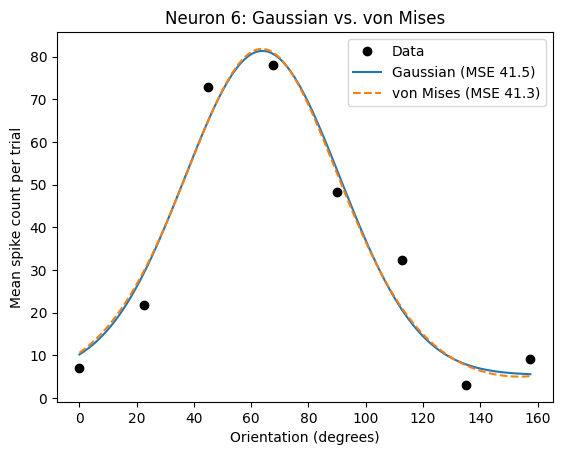

In [195]:
# von Mises MSE, and compare with the Gaussian visually
y_pred_vm = von_mises(angles, *params_vm)
mse_vm = np.mean((y - y_pred_vm) ** 2)
print(f"Gaussian MSE  = {mse_gauss:.2f}")
print(f"von Mises MSE = {mse_vm:.2f}")

plt.plot(angles, y, 'o', color='black', label='Data')
plt.plot(theta_fine, gaussian(theta_fine, *params), label=f'Gaussian (MSE {mse_gauss:.1f})')
plt.plot(theta_fine, von_mises(theta_fine, *params_vm), '--', label=f'von Mises (MSE {mse_vm:.1f})')
plt.xlabel('Orientation (degrees)')
plt.ylabel('Mean spike count per trial')
plt.title(f'Neuron {my_neuron}: Gaussian vs. von Mises')
plt.legend()
plt.show()

1. The von Mises model fits nearly identical, with a MSE difference of only 0.2.Maybe there is a slight observable difference no the edge where the von Mises curve dips a little lower near 150 degree, since it is a periodic funciton and has to connect smoothly back to its value at 0 degrees.
2. Very close to the Gaussian estimate of 63.9 degrees. Both models agree that neuron's true preferred orientation are between 45 and 67.5 degrees.
3. κ is the concentration parameter; it shows how tightly the neuron's response is concentrated around it preffered orientation. Larger kappa means a more sharply tuned curve, inverse to Gaussian's sigma meaning.
4. cosine repeats every 360, but orientation repeats every 180 since grating at theta is identical to one at theta +180. So this model treats the two as the same stimulus. Without the 2, the model would treat as independent stimulus.
5. Very slightly, probably neglible. The MSE did decrease from Gaussian MSE 41.53 to von Mises MSE 41.28, which was expected.
6. I would definitely choose von Mises model. For my neuron it was inapplicable, but for other neurons it will reflect the true circularity of orientation while maintiing the same parameters and remaining biologically relevant or interpreable.

In [196]:
   spread = np.zeros((8, 159))
   for code in range(1, 9):
       spread[code - 1] = counts[stim == code].std(axis=0)

In [197]:
# Noise= from paper they used Fano factor
#Fano factor: variance / mean, per orientation, then averaged per neuron
fano = (spread ** 2) / tuning                    # spread was the std, so spread**2 is the variance
fano_mean = np.nanmean(fano, axis=0)             # average over the 8 orientations, skipping any nan

print(f"Neuron {my_neuron} Fano factor: {fano_mean[my_neuron - 1]:.2f}")

# noisiest neurons that still fire well (peak >= 10) and are tuned (OTI >= 0.35)
candidates = fano_mean.copy()
candidates[(d_max < 10) | (oti < 0.35) | np.isnan(oti)] = 0
ranked = np.argsort(candidates)[::-1][:15]

for n in ranked:
    print(f"Neuron {n+1}: Fano {fano_mean[n]:.2f}, OTI {oti[n]:.2f}, peak {d_max[n]:.1f}")

Neuron 6 Fano factor: 1.47
Neuron 107: Fano 5.24, OTI 0.43, peak 51.9
Neuron 82: Fano 4.37, OTI 0.42, peak 11.1
Neuron 76: Fano 4.29, OTI 0.51, peak 89.5
Neuron 150: Fano 3.84, OTI 0.87, peak 78.9
Neuron 148: Fano 3.81, OTI 0.88, peak 95.4
Neuron 80: Fano 3.71, OTI 0.93, peak 26.5
Neuron 83: Fano 3.70, OTI 0.38, peak 31.4
Neuron 92: Fano 3.58, OTI 0.47, peak 33.3
Neuron 137: Fano 3.53, OTI 0.39, peak 29.3
Neuron 154: Fano 3.43, OTI 0.66, peak 38.7
Neuron 105: Fano 3.37, OTI 0.81, peak 23.4
Neuron 152: Fano 3.37, OTI 0.76, peak 34.8
Neuron 146: Fano 3.31, OTI 0.67, peak 19.1
Neuron 129: Fano 3.30, OTI 0.53, peak 23.3
Neuron 90: Fano 3.27, OTI 0.64, peak 21.5


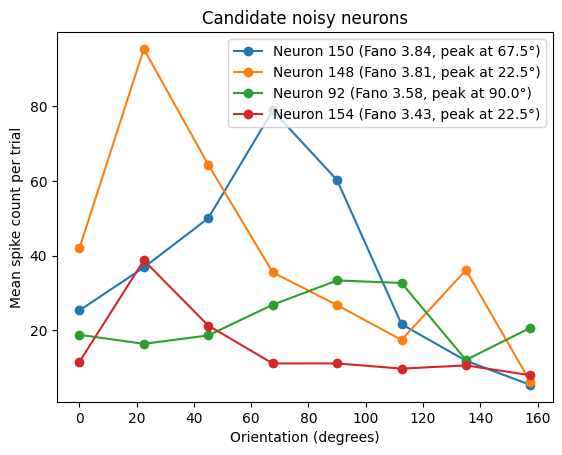

In [198]:
# candidate noisy neurons: shape and preferred orientation
for n in [150, 148, 92, 154]:
    col = n - 1
    pref = angles[np.argmax(tuning[:, col])]
    plt.plot(angles, tuning[:, col], 'o-', label=f'Neuron {n} (Fano {fano_mean[col]:.2f}, peak at {pref:.1f}°)')

plt.xlabel('Orientation (degrees)')
plt.ylabel('Mean spike count per trial')
plt.title('Candidate noisy neurons')
plt.legend()
plt.show()

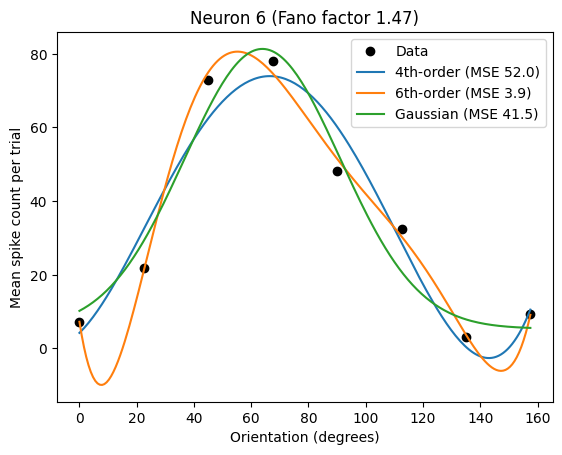

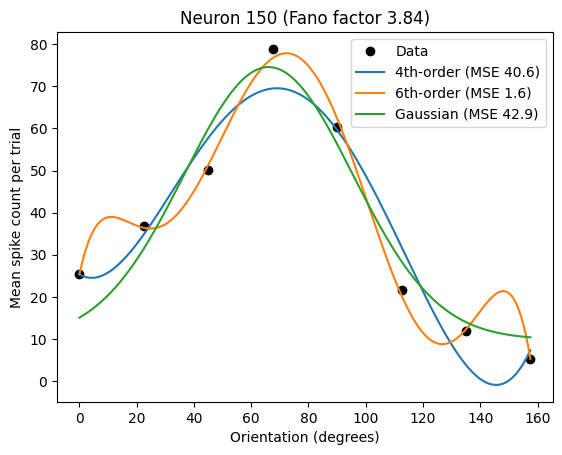

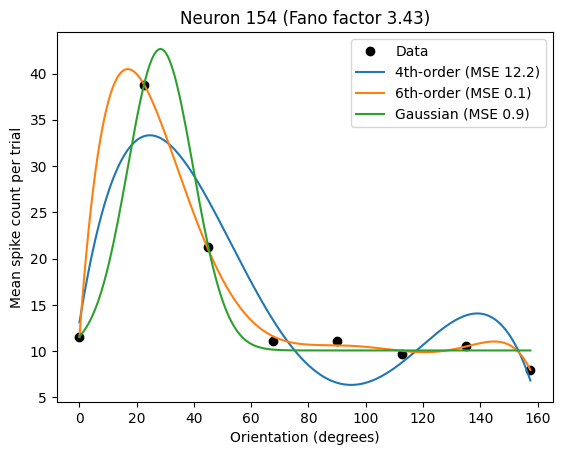

            4th-order poly  6th-order poly  Gaussian
Neuron 6             52.02            3.90     41.53
Neuron 150           40.62            1.63     42.94
Neuron 154           12.16            0.09      0.86


In [199]:
# Part 5: fit 3 models (4th-order poly, 6th-order poly, Gaussian) to 3 neurons and compare MSE
import pandas as pd

study_neurons = [6, 150, 154]                    # 6 = low-noise reference; 150, 154 = noisy
model_names = ['4th-order poly', '6th-order poly', 'Gaussian']
mse_table = np.zeros((3, 3))                     # rows = neurons, columns = models

for i, n in enumerate(study_neurons):
    yn = tuning[:, n - 1]                        # this neuron's 8 mean responses
    peak_angle = angles[np.argmax(yn)]           # angle of its highest mean, used as a starting guess

    # fit the three models
    b4 = np.polyfit(angles, yn, 4)
    b6 = np.polyfit(angles, yn, 6)
    p0_g = [yn.min(), yn.max() - yn.min(), peak_angle, 25]     # [B, A, mu, sigma] guesses
    pg, _ = curve_fit(gaussian, angles, yn, p0=p0_g, maxfev=10000)

    # MSE of each model at the 8 real angles
    preds = [np.polyval(b4, angles), np.polyval(b6, angles), gaussian(angles, *pg)]
    for j in range(3):
        mse_table[i, j] = np.mean((yn - preds[j]) ** 2)

    # one plot per neuron
    plt.plot(angles, yn, 'o', color='black', label='Data')
    plt.plot(theta_fine, np.polyval(b4, theta_fine), label=f'4th-order (MSE {mse_table[i, 0]:.1f})')
    plt.plot(theta_fine, np.polyval(b6, theta_fine), label=f'6th-order (MSE {mse_table[i, 1]:.1f})')
    plt.plot(theta_fine, gaussian(theta_fine, *pg), label=f'Gaussian (MSE {mse_table[i, 2]:.1f})')
    plt.xlabel('Orientation (degrees)')
    plt.ylabel('Mean spike count per trial')
    plt.title(f'Neuron {n} (Fano factor {fano_mean[n - 1]:.2f})')
    plt.legend()
    plt.show()

# summary table
print(pd.DataFrame(mse_table, index=[f'Neuron {n}' for n in study_neurons], columns=model_names).round(2))

The von Mises starting guess for A uses the same logic you used by hand: the peak rise should be about max − min, and since the peak is B + A·e^κ, a starting κ of 1.5 means A ≈ (max − min) ÷ e^1.5.

1. For noisier neurons, the 6th polynomial had lowest MSE because it had the most parameters and could pass very through almost all of the points. Between the remaining two models of the 4th order and Gaussian, the results actually differed. Neuron 150 fit alsmost equally well to 4th order and Gaussian model. For Neuron 154, the Gaussian fit far better.
2. For loise noise reference neuron 6, the Gaussian clearly outperformed the 4th order. For noisier neuron 150, this advantage disappeared, and 4th order achieved lower MSE. This makes sense with noise favoring flexible models: random fluctuations in the data can be partially fitted by a poloynomial but not by the Gaussian, whose shape is constrained to a smooth bump.
3. MSE rewards flexibility: adding parameters decrease it, so the 6th order polynomial has lowest MSE for every neuron, but its curve oscillates between the data points, fiting the specific noise instead of the underlying tuning. So it would perform poorly in new data predictions, overfitting it.
4. I would select Gaussian or the von Mises because it's shape parallels orientation tuning.

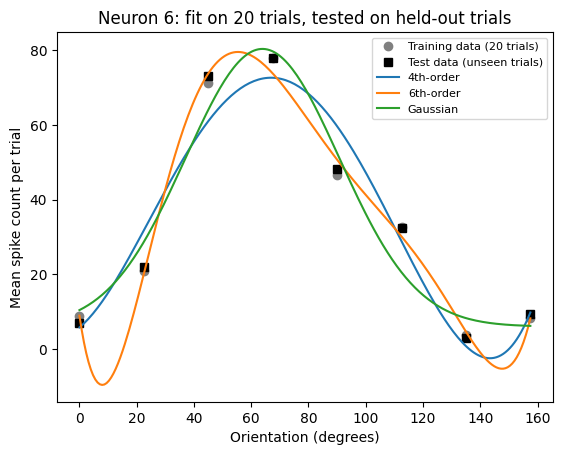

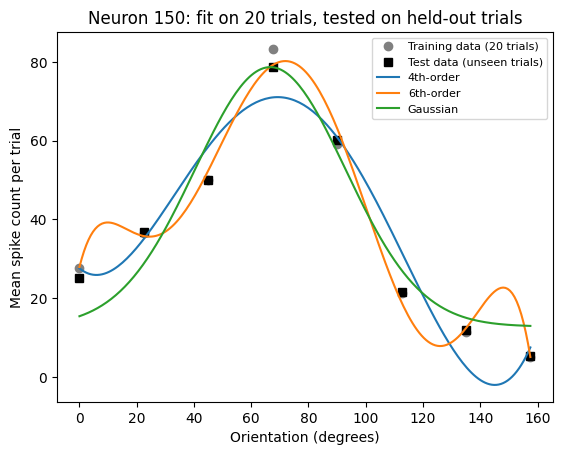

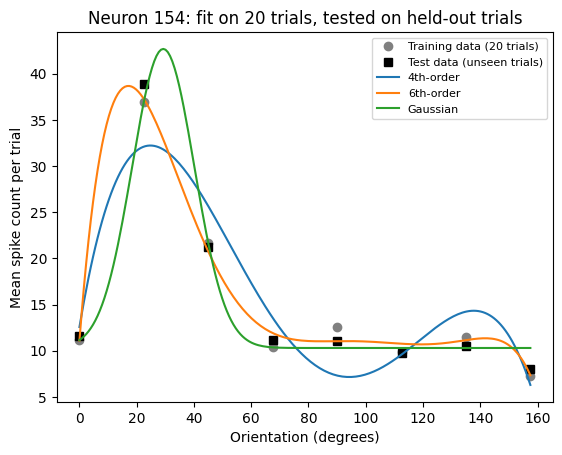

TRAINING MSE
            4th-order poly  6th-order poly  Gaussian
Neuron 6             57.22            5.92     40.40
Neuron 150           52.82            5.92     54.81
Neuron 154           10.98            0.80      1.95

TEST MSE (generalization)
            4th-order poly  6th-order poly  Gaussian
Neuron 6             52.79            4.97     42.14
Neuron 150           41.63            3.77     45.11
Neuron 154           12.76            0.67      1.35


In [200]:
# Held-out test: fit on 20 trials per orientation, test on the remaining 380
rng = np.random.default_rng(seed=0)       # random number generator; seed=0 makes the split reproducible
n_train = 20                              # training trials per orientation

train_table = np.zeros((3, 3))            # rows = neurons, columns = models
test_table = np.zeros((3, 3))

for i, n in enumerate(study_neurons):
    col = n - 1
    train_means = np.zeros(8)
    test_means = np.zeros(8)

    # split each orientation's trials into train and test
    for code in range(1, 9):
        trial_idx = np.where(stim == code)[0]          # positions of this orientation's 400 trials
        shuffled = rng.permutation(trial_idx)          # random order
        train_means[code - 1] = counts[shuffled[:n_train], col].mean()   # first 20 trials
        test_means[code - 1] = counts[shuffled[n_train:], col].mean()    # remaining 380

    # fit the three models on the TRAINING curve only
    b4 = np.polyfit(angles, train_means, 4)
    b6 = np.polyfit(angles, train_means, 6)
    peak_angle = angles[np.argmax(train_means)]
    p0_g = [train_means.min(), train_means.max() - train_means.min(), peak_angle, 25]
    pg, _ = curve_fit(gaussian, angles, train_means, p0=p0_g, maxfev=10000)

    preds = [np.polyval(b4, angles), np.polyval(b6, angles), gaussian(angles, *pg)]
    for j in range(3):
        train_table[i, j] = np.mean((train_means - preds[j]) ** 2)   # error on data it was fitted to
        test_table[i, j] = np.mean((test_means - preds[j]) ** 2)     # error on unseen trials

    # plot: training curve, test curve, and the three fits
    plt.plot(angles, train_means, 'o', color='gray', label=f'Training data ({n_train} trials)')
    plt.plot(angles, test_means, 's', color='black', label='Test data (unseen trials)')
    plt.plot(theta_fine, np.polyval(b4, theta_fine), label='4th-order')
    plt.plot(theta_fine, np.polyval(b6, theta_fine), label='6th-order')
    plt.plot(theta_fine, gaussian(theta_fine, *pg), label='Gaussian')
    plt.xlabel('Orientation (degrees)')
    plt.ylabel('Mean spike count per trial')
    plt.title(f'Neuron {n}: fit on {n_train} trials, tested on held-out trials')
    plt.legend(fontsize=8)
    plt.show()

labels = [f'Neuron {n}' for n in study_neurons]
print("TRAINING MSE")
print(pd.DataFrame(train_table, index=labels, columns=model_names).round(2))
print("\nTEST MSE (generalization)")
print(pd.DataFrame(test_table, index=labels, columns=model_names).round(2))

In [201]:
# Leave-one-orientation-out: can each model predict an orientation it never saw?
loo_table = np.zeros((3, 3))                   # rows = neurons, columns = models

for i, n in enumerate(study_neurons):
    yn = tuning[:, n - 1]
    sq_errors = np.zeros((8, 3))               # one row per held-out angle

    for k in range(8):
        keep = np.arange(8) != k               # True for every angle except angle k
        x_train, y_train = angles[keep], yn[keep]

        b4 = np.polyfit(x_train, y_train, 4)
        b6 = np.polyfit(x_train, y_train, 6)
        p0_g = [y_train.min(), y_train.max() - y_train.min(), x_train[np.argmax(y_train)], 25]
        pg, _ = curve_fit(gaussian, x_train, y_train, p0=p0_g, maxfev=10000)

        x_new = angles[k]                      # the hidden angle
        preds = np.array([np.polyval(b4, x_new), np.polyval(b6, x_new), gaussian(x_new, *pg)])
        sq_errors[k] = (yn[k] - preds) ** 2

    loo_table[i] = sq_errors.mean(axis=0)      # average over the 8 held-out angles

print("LEAVE-ONE-ORIENTATION-OUT MSE (predicting a new orientation)")
print(pd.DataFrame(loo_table, index=labels, columns=model_names).round(2))

LEAVE-ONE-ORIENTATION-OUT MSE (predicting a new orientation)
            4th-order poly  6th-order poly  Gaussian
Neuron 6           2057.17        27383.68    169.78
Neuron 150          870.56        11431.44    199.04
Neuron 154          730.62          609.85    125.15
